In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Load Dataset

In [6]:
df = pd.read_csv('dynamic_pricing (1).csv')
df.head()

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


## Check Data

In [7]:
print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())

(1000, 10)
Number_of_Riders           0
Number_of_Drivers          0
Location_Category          0
Customer_Loyalty_Status    0
Number_of_Past_Rides       0
Average_Ratings            0
Time_of_Booking            0
Vehicle_Type               0
Expected_Ride_Duration     0
Historical_Cost_of_Ride    0
dtype: int64
0


## Basic Information

In [8]:
df.describe()

,Number_of_Riders,Number_of_Drivers,Number_of_Past_Rides,Average_Ratings,Expected_Ride_Duration,Historical_Cost_of_Ride
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,60.372000,27.076000,50.031000,4.257220,99.58800,372.502623
std,23.701506,19.068346,29.313774,0.435781,49.16545,187.158756
min,20.000000,5.000000,0.000000,3.500000,10.00000,25.993449
25%,40.000000,11.000000,25.000000,3.870000,59.75000,221.365202
50%,60.000000,22.000000,51.000000,4.270000,102.00000,362.019426
75%,81.000000,38.000000,75.000000,4.632500,143.00000,510.497504
max,100.000000,89.000000,100.000000,5.000000,180.00000,836.116419


## X And y

In [ ]:
X = df.drop("Historical_Cost_of_Ride", axis=1)
y = df["Historical_Cost_of_Ride"]

## Numerical + Categorical

In [11]:
num = X.select_dtypes(include=np.number).columns
cat = X.select_dtypes(include="str").columns

print("Numerical columns:", num.tolist())
print("Categorical columns:", cat.tolist())

Numerical columns: ['Number_of_Riders', 'Number_of_Drivers', 'Number_of_Past_Rides', 'Average_Ratings', 'Expected_Ride_Duration']
Categorical columns: ['Location_Category', 'Customer_Loyalty_Status', 'Time_of_Booking', 'Vehicle_Type']


In [12]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)
], remainder="passthrough")

## EDA
Fare Distribution

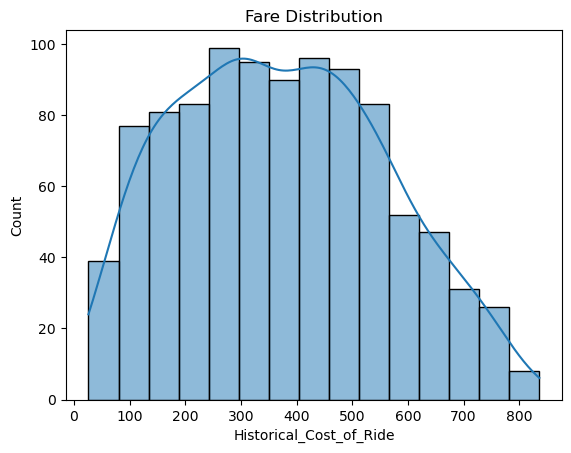

In [14]:
sns.histplot(df["Historical_Cost_of_Ride"], kde=True)
plt.title("Fare Distribution")
plt.show()

## Duration vs Fare

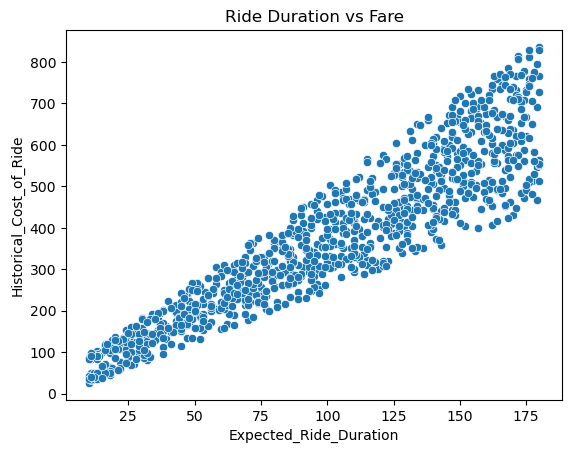

In [15]:
sns.scatterplot(
    data=df,
    x="Expected_Ride_Duration",
    y="Historical_Cost_of_Ride"
)
plt.title("Ride Duration vs Fare")
plt.show()

## Vehicle Type vs Average Fare

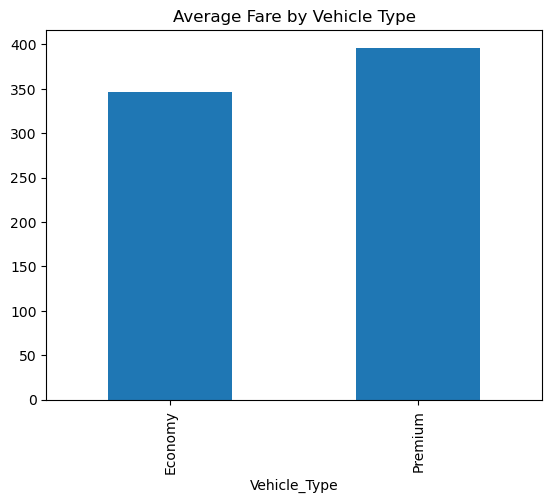

In [16]:
df.groupby("Vehicle_Type")["Historical_Cost_of_Ride"].mean().plot(kind="bar")
plt.title("Average Fare by Vehicle Type")
plt.show()

## Vehicle Type vs Average Rating

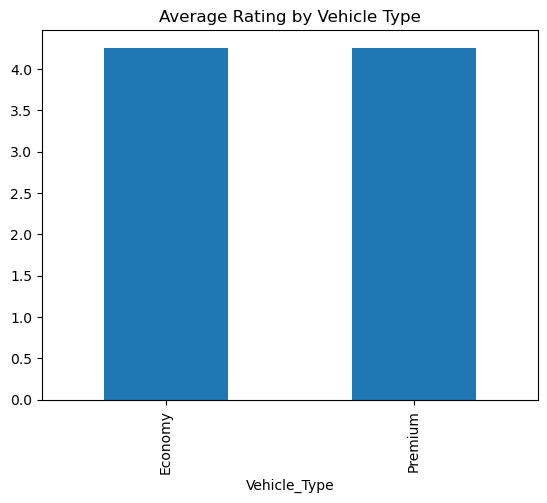

In [17]:
df.groupby("Vehicle_Type")["Average_Ratings"].mean().plot(kind="bar")
plt.title("Average Rating by Vehicle Type")
plt.show()

## Booking Time vs Fare

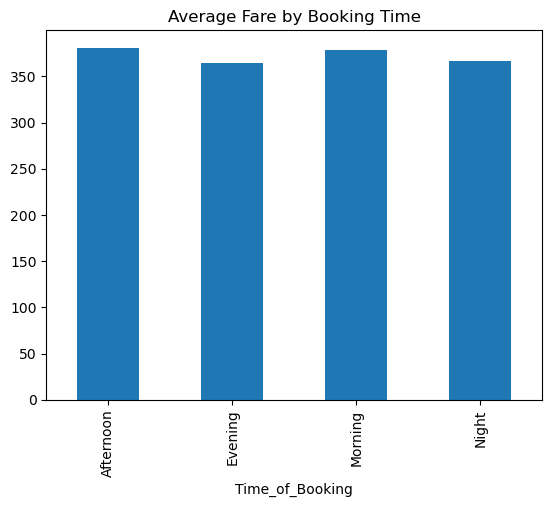

In [18]:
df.groupby("Time_of_Booking")["Historical_Cost_of_Ride"].mean().plot(kind="bar")
plt.title("Average Fare by Booking Time")
plt.show()

## Correlation Heatmap

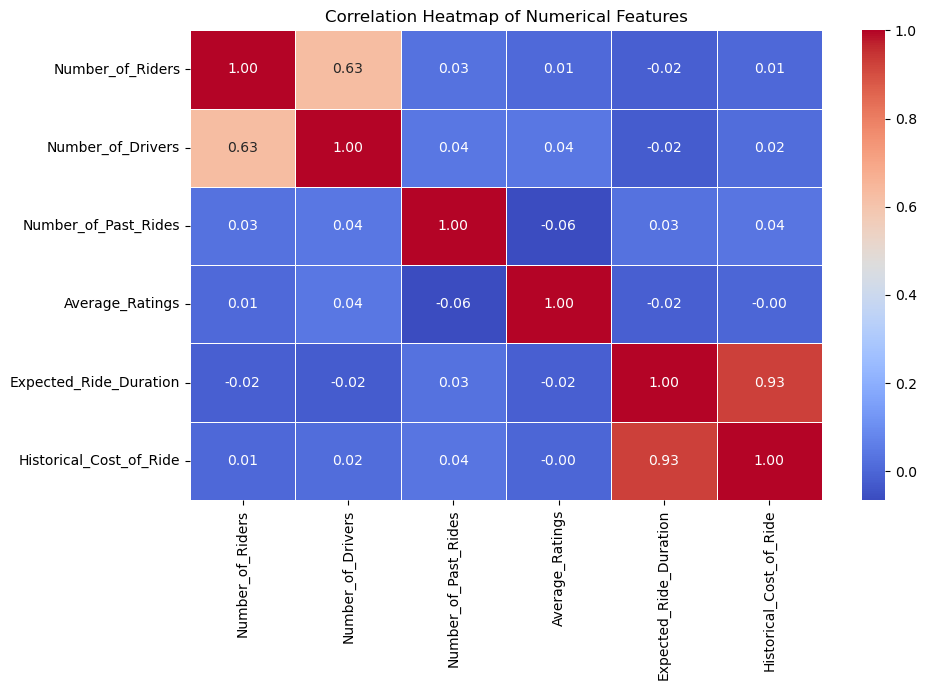

In [20]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

# Model Building

#### Train-Test Split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 9)
Testing data: (200, 9)


### Linear Regression

In [23]:
lr_model = Pipeline([
    ("preprocess", preprocess),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Linear Regression completed")

Linear Regression completed


#### Decision Tree

In [24]:
dt_model = Pipeline([
    ("preprocess", preprocess),
    ("model", DecisionTreeRegressor(random_state=42))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree completed")

Decision Tree completed


#### Random Forest

In [25]:
rf_model = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest completed")

Random Forest completed


# Model Evaluation

#### Evaluation Function

In [26]:
def evaluate(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(name)
    print("MAE :", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2  :", round(r2, 3))
    print()

In [27]:
evaluate("Linear Regression", y_test, lr_pred)
evaluate("Decision Tree", y_test, dt_pred)
evaluate("Random Forest", y_test, rf_pred)

Linear Regression
MAE : 52.56
RMSE: 67.44
R2  : 0.875

Decision Tree
MAE : 72.91
RMSE: 100.46
R2  : 0.723

Random Forest
MAE : 55.19
RMSE: 73.49
R2  : 0.852



# Model Comparison Table

In [28]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    
    "MAE": [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, dt_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, dt_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    
    "R2 Score": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, dt_pred),
        r2_score(y_test, rf_pred)
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,52.561918,67.443316,0.875247
1,Decision Tree,72.906457,100.455278,0.723230
2,Random Forest,55.185592,73.494439,0.851856


# Best Model

In [29]:
best_model = results.loc[
    results["R2 Score"].idxmax()
]

print("Best Model:", best_model["Model"])
print("R2 Score:", round(best_model["R2 Score"], 3))

Best Model: Linear Regression
R2 Score: 0.875


# Comparison Chart

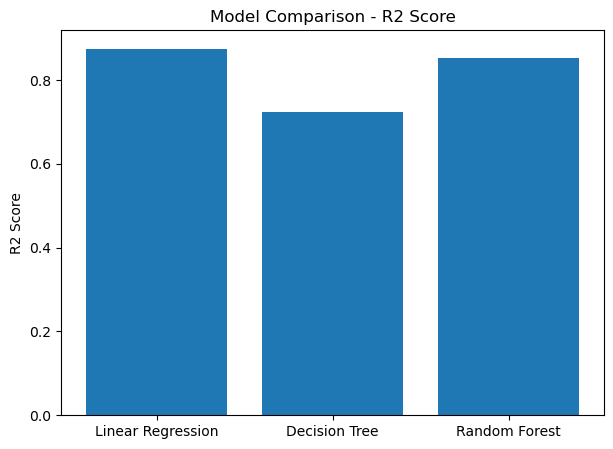

In [30]:
plt.figure(figsize=(7,5))

plt.bar(
    results["Model"],
    results["R2 Score"]
)

plt.title("Model Comparison - R2 Score")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)

plt.show()

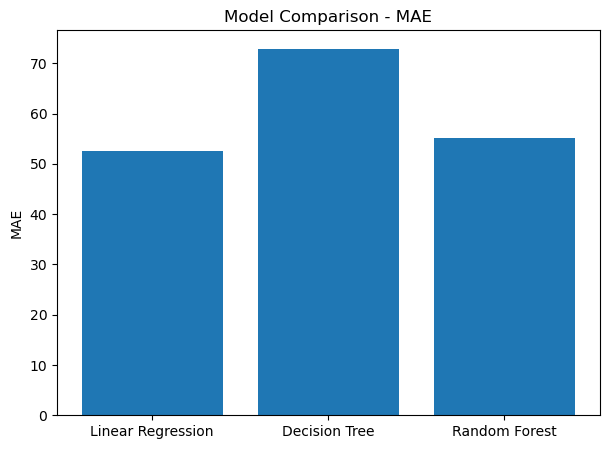

In [31]:
plt.figure(figsize=(7,5))

plt.bar(
    results["Model"],
    results["MAE"]
)

plt.title("Model Comparison - MAE")
plt.ylabel("MAE")
plt.xticks(rotation=0)

plt.show()

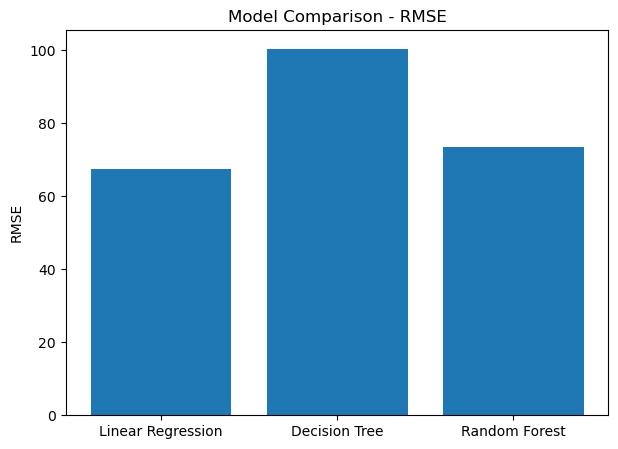

In [32]:
plt.figure(figsize=(7,5))

plt.bar(
    results["Model"],
    results["RMSE"]
)

plt.title("Model Comparison - RMSE")
plt.ylabel("RMSE")
plt.xticks(rotation=0)

plt.show()

# Actual vs Predicted

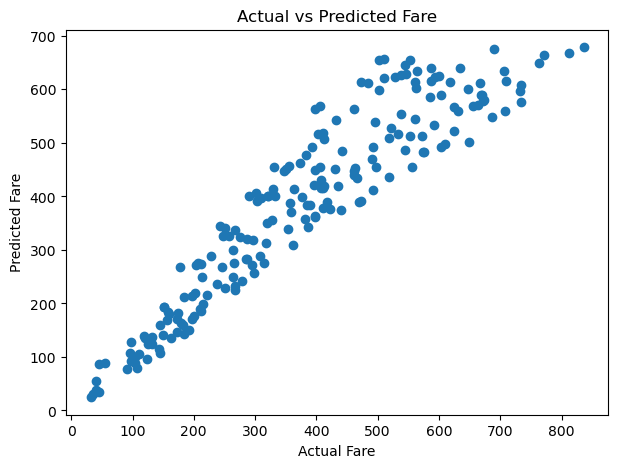

In [33]:
plt.figure(figsize=(7,5))

plt.scatter(
    y_test,
    lr_pred
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Fare")

plt.show()

In [36]:
models = {
    "Linear Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

best_name = results.loc[
    results["R2 Score"].idxmax(),
    "Model"
]

joblib.dump(
    models[best_name],
    "best_model.pkl"
)

print("Best model:", best_name)
print("Model saved successfully")

Best model: Linear Regression
Model saved successfully


# Prediction

In [37]:
new_ride = pd.DataFrame({
    "Number_of_Riders": [50],
    "Number_of_Drivers": [30],
    "Location_Category": ["Urban"],
    "Customer_Loyalty_Status": ["Gold"],
    "Number_of_Past_Rides": [20],
    "Average_Ratings": [4.5],
    "Time_of_Booking": ["Evening"],
    "Vehicle_Type": ["Premium"],
    "Expected_Ride_Duration": [60]
})

prediction = models[best_name].predict(new_ride)

print("Predicted Ride Fare:", round(prediction[0], 2))

Predicted Ride Fare: 248.76
